In [ ]:
import pandas as pd
import numpy as np

In [ ]:
file_path = '/content/RICE.csv'
df = pd.read_csv(file_path)#contains the csv file
df.describe()

,Observation Year,Standard Week,Pest Value,MaxT,MinT,RH1(%),RH2(%),RF(mm),WS(kmph),SSH(hrs),EVP(mm)
count,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000,19404.000000
mean,2000.024789,26.473717,807.944081,31.169006,20.404540,82.190981,53.725763,19.414152,4.501268,6.858529,5.877180
std,9.827306,15.016247,5290.180315,4.904610,5.388381,13.846883,18.948801,39.160009,3.194973,4.176542,6.536221
min,1959.000000,1.000000,0.000000,10.900000,0.800000,9.300000,6.700000,0.000000,0.000000,0.000000,0.000000
25%,1996.000000,13.000000,0.000000,28.800000,17.500000,79.100000,38.000000,0.000000,2.300000,4.900000,2.900000
50%,2001.000000,26.000000,3.000000,30.900000,22.000000,87.300000,56.600000,0.000000,3.700000,7.300000,4.000000
75%,2007.000000,39.000000,92.000000,33.425000,24.400000,91.000000,69.000000,21.400000,5.900000,8.900000,6.000000
max,2011.000000,52.000000,311169.000000,71.600000,30.900000,100.000000,95.100000,444.400000,27.600000,127.100000,68.300000


In [ ]:
df.isnull().sum() #checking for null value, isnull -> to check for missing values

,0
Observation Year,0
Standard Week,0
Pest Value,0
Collection Type,0
MaxT,0
MinT,0
RH1(%),0
RH2(%),0
RF(mm),0
WS(kmph),0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19404 entries, 0 to 19403
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Observation Year  19404 non-null  int64  
 1   Standard Week     19404 non-null  int64  
 2   Pest Value        19404 non-null  float64
 3   Collection Type   19404 non-null  object 
 4   MaxT              19404 non-null  float64
 5   MinT              19404 non-null  float64
 6   RH1(%)            19404 non-null  float64
 7   RH2(%)            19404 non-null  float64
 8   RF(mm)            19404 non-null  float64
 9   WS(kmph)          19404 non-null  float64
 10  SSH(hrs)          19404 non-null  float64
 11  EVP(mm)           19404 non-null  float64
 12  PEST NAME         19404 non-null  object 
 13  Location          19404 non-null  object 
dtypes: float64(9), int64(2), object(3)
memory usage: 2.1+ MB


In [ ]:
df.shape

(19404, 14)

In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df['Observation Year'] = imputer.fit_transform(df[['Observation Year']])
df['Standard Week'] = imputer.fit_transform(df[['Standard Week']])
df['Pest Value'] = imputer.fit_transform(df[['Pest Value']])
df['MaxT'] = imputer.fit_transform(df[['MaxT']])
df['MinT'] = imputer.fit_transform(df[['MinT']])
df['RH1(%)'] = imputer.fit_transform(df[['RH1(%)']])
df['RH2(%)'] = imputer.fit_transform(df[['RH2(%)']])
df['RF(mm)'] = imputer.fit_transform(df[['RF(mm)']])
df['WS(kmph)'] = imputer.fit_transform(df[['WS(kmph)']])
df['SSH(hrs)'] = imputer.fit_transform(df[['SSH(hrs)']])
df['EVP(mm)'] = imputer.fit_transform(df[['EVP(mm)']])

In [ ]:
df.isnull().sum() #checking for null value, isnull -> to check for missing values

,0
Observation Year,0
Standard Week,0
Pest Value,0
Collection Type,0
MaxT,0
MinT,0
RH1(%),0
RH2(%),0
RF(mm),0
WS(kmph),0


In [ ]:
# lets see the unique values of columns
for col in df.columns:
  if df[col].dtype=='object':
    print()
    print(col)
    print(df[col].unique())


Collection Type
['Number/hill' 'Number/Light trap' 'Percent Damage'
 'Number/Pheromone trap' 'Percentage']

PEST NAME
['Brownplanthopper' 'Gallmidge' 'Greenleafhopper' 'LeafFolder'
 'Yellowstemborer' 'Caseworm' 'Miridbug' 'Whitebackedplanthopper'
 'ZigZagleafhopper' 'LeafBlast' 'NeckBlast']

Location
['Cuttack' 'Ludhiana' 'Maruteru' 'Palampur' 'Raipur' 'Rajendranagar']


In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt

In [ ]:
px.pie(
    df.groupby('Location', as_index=False)['PEST NAME'].count(),
    values='PEST NAME',
    names='Location',
    labels={'PEST NAME':'Count'},
    template='plotly_dark',
    color_discrete_sequence=px.colors.sequential.Plasma,
    hole=.5,
    title='<b> Pest Observations in Different Locations</b>'
)

In [ ]:
px.box(df, x='Location', y='Pest Value', color='Location',
       template='plotly_dark',
       title='<b> Pest Value in Different Locations')

In [ ]:
px.scatter(
    df,
    x='MaxT',
    y='Pest Value',
    color='Location',
    size='MaxT',
    labels={'MaxT':'Maximum Temperature (°C)', 'Pest Value':'Pest Value'},
    template='plotly_dark',
    title='<b> Maximum Temperature Versus Pest Value in Different Locations'
)

In [ ]:
px.scatter(
    df,
    x='RF(mm)',
    y='Pest Value',
    color='Location',
    size='Pest Value',
    template='plotly_dark',
    title='<b> Rainfall Vs Pest Value in Different Locations'
)

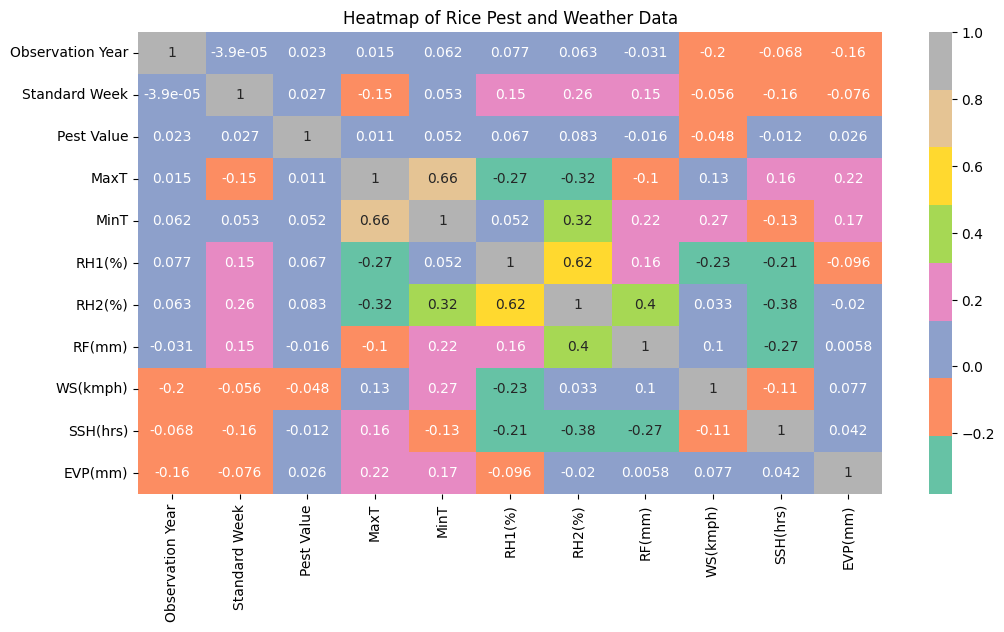

In [ ]:
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="Set2")
plt.title("Heatmap of Rice Pest and Weather Data")
plt.show()